# 🤖 Sprint 3 — Modeling (Supervised Learning)
**Entrada:** artefactos do Sprint 2 · **Saídas:** `models/fitted_models.joblib`, `models/tf_mlp.keras`, `reports/model_comparison.csv`

Modelos do roadmap aplicados à **classificação**: Regressão Logística, Árvore de Decisão, kNN, Naïve Bayes (Gaussian/Multinomial/Bernoulli), SVM (linear e RBF), Ensembles (Random Forest = bagging; AdaBoost, Gradient Boosting, XGBoost = boosting) e **uma rede em TensorFlow**.
> A *Regressão Linear* do roadmap não se aplica (alvo categórico); a Regressão Logística é a sua versão para classificação.

A seleção do melhor modelo usa a **validação**; o **teste** só é usado no Sprint 4.

In [1]:
import os, sys, glob, time, warnings, json
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from scipy import stats
import joblib
warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
RANDOM_STATE = 42
for d in ["models", "reports", "data"]:
    os.makedirs(d, exist_ok=True)
sys.path.insert(0, os.path.abspath("src"))   # executar o notebook na raiz do projeto (onde está a pasta src/)

In [2]:
from utils import evaluate_model
S = joblib.load("data/splits.joblib"); CFG = joblib.load("data/config.joblib")
X_train, X_val, X_test = S["X_train"], S["X_val"], S["X_test"]
y_train, y_val, y_test, le = S["y_train"], S["y_val"], S["y_test"], S["label_encoder"]
CLASS_WEIGHT, N_CLASSES = CFG["CLASS_WEIGHT"], CFG["N_CLASSES"]
prep_sparse, prep_dense = joblib.load("models/prep_sparse.joblib"), joblib.load("models/prep_dense.joblib")

Xs_train, Xs_val = prep_sparse.transform(X_train), prep_sparse.transform(X_val)
Xd_train, Xd_val = prep_dense.transform(X_train), prep_dense.transform(X_val)
print("Esparso:", Xs_train.shape, "| Denso:", Xd_train.shape, "| classes:", N_CLASSES, "| class_weight:", CLASS_WEIGHT)

Esparso: (15143, 5000) | Denso: (15143, 200) | classes: 22 | class_weight: None


In [4]:
!pip install xgboost

  Using cached xgboost-3.4.1-py3-none-win_amd64.whl.metadata (2.0 kB)
Using cached xgboost-3.4.1-py3-none-win_amd64.whl (48.9 MB)


## 3.1 Modelos scikit-learn

In [5]:
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB, BernoulliNB, GaussianNB
from sklearn.svm import LinearSVC, SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier, HistGradientBoostingClassifier

sparse_models = {
    "LogisticRegression": LogisticRegression(max_iter=1000, class_weight=CLASS_WEIGHT),
    "MultinomialNB": MultinomialNB(alpha=0.1),
    "BernoulliNB": BernoulliNB(alpha=0.1),
    "LinearSVC (SVM linear)": LinearSVC(class_weight=CLASS_WEIGHT),
    "kNN (cosine)": KNeighborsClassifier(n_neighbors=5, metric="cosine", algorithm="brute", n_jobs=-1),
    "DecisionTree": DecisionTreeClassifier(max_depth=40, class_weight=CLASS_WEIGHT, random_state=RANDOM_STATE),
    "RandomForest (bagging)": RandomForestClassifier(n_estimators=200, n_jobs=-1, class_weight=CLASS_WEIGHT, random_state=RANDOM_STATE),
}
dense_models = {
    "GaussianNB": GaussianNB(),
    "SVC RBF (SVM não-linear)": SVC(kernel="rbf", C=5, class_weight=CLASS_WEIGHT),
    "AdaBoost": AdaBoostClassifier(n_estimators=100, learning_rate=0.5, random_state=RANDOM_STATE),
    "GradientBoosting (Hist)": HistGradientBoostingClassifier(max_iter=100, random_state=RANDOM_STATE),
}
try:
    from xgboost import XGBClassifier
    dense_models["XGBoost"] = XGBClassifier(n_estimators=150, tree_method="hist", n_jobs=-1, random_state=RANDOM_STATE, eval_metric="mlogloss")
except ImportError:
    print("xgboost não instalado -> ignorado (pip install xgboost)")

results, fitted, prep_kind = [], {}, {}
for kind, models, Xtr, Xva in [("sparse", sparse_models, Xs_train, Xs_val), ("dense", dense_models, Xd_train, Xd_val)]:
    for name, m in models.items():
        print("A treinar:", name, end=" ... ")
        try:
            r = evaluate_model(name, m, Xtr, y_train, Xva, y_val)
            results.append(r); fitted[name] = m; prep_kind[name] = kind
            print(f"F1={r['f1_macro']:.4f} ({r['fit_time_s']}s)")
        except Exception as e:
            print("FALHOU:", e)

A treinar: LogisticRegression ... F1=0.9836 (3.07s)
A treinar: MultinomialNB ... F1=0.9788 (0.05s)
A treinar: BernoulliNB ... F1=0.9784 (0.06s)
A treinar: LinearSVC (SVM linear) ... F1=0.9822 (7.96s)
A treinar: kNN (cosine) ... F1=0.9802 (0.01s)
A treinar: DecisionTree ... F1=0.9521 (14.62s)
A treinar: RandomForest (bagging) ... F1=0.9798 (23.85s)
A treinar: GaussianNB ... F1=0.9679 (0.21s)
A treinar: SVC RBF (SVM não-linear) ... F1=0.9830 (10.93s)
A treinar: AdaBoost ... F1=0.4774 (106.7s)
A treinar: GradientBoosting (Hist) ... F1=0.9807 (12.03s)
A treinar: XGBoost ... F1=0.9836 (46.87s)


## 3.2 Modelo TensorFlow (MLP sobre TF-IDF)

In [6]:
try:
    import tensorflow as tf
    from sklearn.metrics import accuracy_score, f1_score
    tf.random.set_seed(RANDOM_STATE)
    Xt_train, Xt_val = Xs_train.astype("float32").toarray(), Xs_val.astype("float32").toarray()
    tf_model = tf.keras.Sequential([
        tf.keras.layers.Input(shape=(Xt_train.shape[1],)),
        tf.keras.layers.Dense(256, activation="relu"), tf.keras.layers.Dropout(0.3),
        tf.keras.layers.Dense(128, activation="relu"), tf.keras.layers.Dropout(0.2),
        tf.keras.layers.Dense(N_CLASSES, activation="softmax"),
    ])
    tf_model.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    es = tf.keras.callbacks.EarlyStopping(patience=2, restore_best_weights=True, monitor="val_loss")
    t0 = time.time()
    hist = tf_model.fit(Xt_train, y_train, validation_data=(Xt_val, y_val), epochs=15, batch_size=128, callbacks=[es], verbose=2)
    fit_t = time.time() - t0
    pred = tf_model.predict(Xt_val, verbose=0).argmax(1)
    results.append({"model": "TensorFlow MLP", "accuracy": accuracy_score(y_val, pred), "f1_macro": f1_score(y_val, pred, average="macro"),
                    "fit_time_s": round(fit_t, 2), "pred_time_s": np.nan})
    tf_model.save("models/tf_mlp.keras")
    pd.DataFrame(hist.history)[["loss", "val_loss"]].plot(title="TensorFlow — curva de aprendizagem"); plt.show()
except ImportError:
    print("TensorFlow não instalado -> pip install tensorflow")

TensorFlow não instalado -> pip install tensorflow


## 3.3 Comparação (validação) e guardar modelos

,model,accuracy,f1_macro,fit_time_s,pred_time_s
0,XGBoost,0.9834,0.9836,46.87,0.02
1,LogisticRegression,0.9834,0.9836,3.07,0.01
2,SVC RBF (SVM não-linear),0.9827,0.9830,10.93,4.27
3,LinearSVC (SVM linear),0.9821,0.9822,7.96,0.01
4,GradientBoosting (Hist),0.9803,0.9807,12.03,0.06
5,kNN (cosine),0.9797,0.9802,0.01,4.40
6,RandomForest (bagging),0.9794,0.9798,23.85,0.32
7,MultinomialNB,0.9781,0.9788,0.05,0.01
8,BernoulliNB,0.9778,0.9784,0.06,0.02
9,GaussianNB,0.9673,0.9679,0.21,0.30


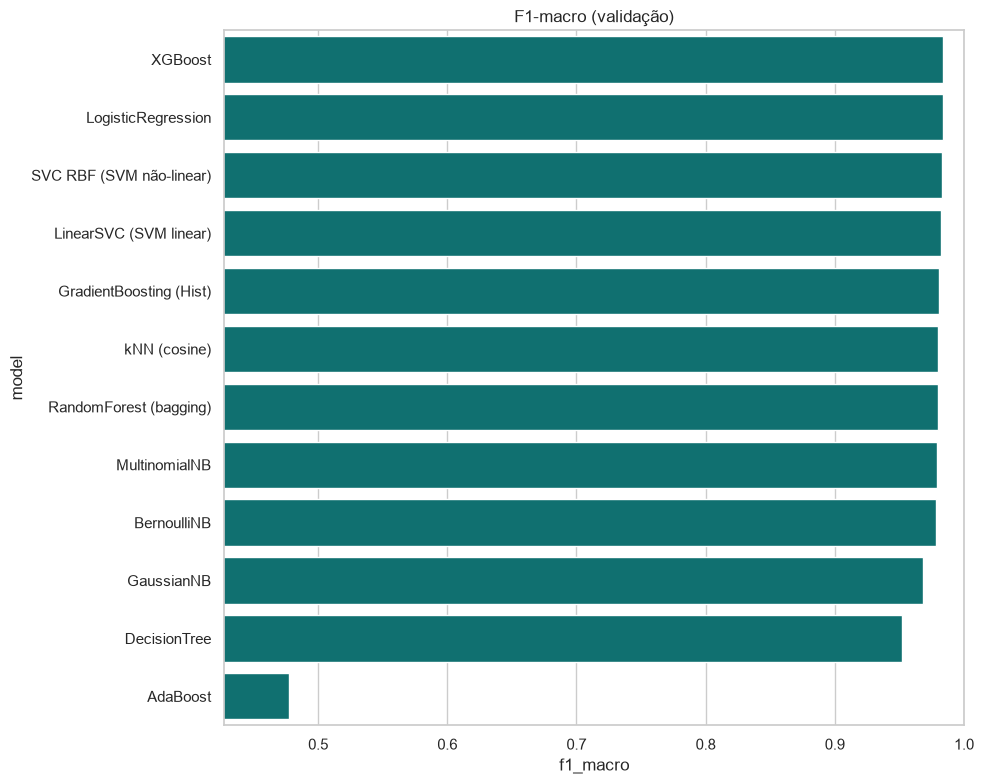

Guardado: models/fitted_models.joblib, reports/model_comparison.csv


In [8]:
res = pd.DataFrame(results).sort_values("f1_macro", ascending=False).reset_index(drop=True)
display(res.round(4))
fig, ax = plt.subplots(figsize=(10, 0.5 * len(res) + 2))
sns.barplot(data=res, y="model", x="f1_macro", ax=ax, color="teal")
ax.set_xlim(max(0, res["f1_macro"].min() - 0.05), 1.0); ax.set_title("F1-macro (validação)")
plt.tight_layout(); plt.show()

res.to_csv("reports/model_comparison.csv", index=False)
joblib.dump({"fitted": fitted, "prep_kind": prep_kind}, "models/fitted_models.joblib")
print("Guardado: models/fitted_models.joblib, reports/model_comparison.csv")

**Próximo passo:** `04_Sprint4_Evaluation_Deployment.ipynb`.